In [1]:
import jax_sn as jsn
%load_ext autoreload
%autoreload 2
import jax_sbgeom

import jax.numpy as jnp
import numpy as onp
from typing import Tuple
import jax
import numpy as onp
from functools import partial
jax.config.update("jax_enable_x64", True)

import pyvista as pv

def remove_zeros(array):
    a = onp.array(array)
    a[onp.abs(a) < 1e-14] = 0.0
    return a

from jax_sn.domain.geometric_domain import GeometricDomain, TopologicalSortedAngle
from jax_sn.solution_domain.solution_domain import FEMMatrices, PrecomputedGeometricData
from jax_sn.domain.geometric_domain import CrossSectionData, CrossSectionDataSingleGroup
from jax_sn.source import Source
from jax_sn.operators.transport_operator import TransportOperatorBatched, TransportOperatorMultipleAnglesVmap, TransportOperatorVmap
from jax_sn.operators.mass_operator import MassOperator
from jax_sn.operators.moment_operator import MomentOperator

from typing import List
from jax_sn.tools.mesh_tools import _pad_last_dimension
import matplotlib.pyplot as plt
from dataclasses import dataclass
onp.set_printoptions(linewidth = 200)
from finite_elements.test_moment_scatter_operator import _setup_all_sb

In [2]:
from jax_sn.domain.domain_generation import create_cartesian_setup
from jax_sn.solution_domain import BasixLagrangianSimplex
from jax_sn.solution_domain import SolutionDomain
from jax_sn.domain import CrossSectionData, Domain
from jax_sn.source import Source

In [3]:
def setup_anisotropic(dim, degree, n_elem_regions, d_other_dim, n_other_dim):

    water = CrossSectionData(jnp.array([15.2090, 24.4140]), jnp.array([[[5.5069, 0.0], 
                                                                        [6.6227, 11.4080]], 
                                                                        [[1.158567, 0.0],
                                                                         [1.1234767, 2.4733]]]))
    
    iron = CrossSectionData(jnp.array([30.3110, 26.8760]), jnp.array([[[18.25, 0.0], 
                                                                       [6.45294, 21.3570]], 
                                                                      [[4.363, 0.0],
                                                                       [-0.003508, 2.3457]]]))
    void = CrossSectionData.constant(1e-10, 2, 2)
        


    other_dims   = [[(d_other_dim, n_other_dim)]]*(dim - 1)

    region_sizes = [0.2, 0.1,     0.5,   0.2,  0.1,  0.1,    0.1]
    xs_regions   = [water, water, water, iron, void, water , void]

    region_size_res = [(size, n_elem) for size, n_elem in zip(region_sizes, n_elem_regions)]

    source_eg0 = [0.0, 9.7702e4, 0, 0,0,0,0]
    
    
    
    verts, conn, cross_sections, sources = create_cartesian_setup(dim, [region_size_res] + other_dims, xs_regions, source_eg0, 0)
    element_type                         = BasixLagrangianSimplex(degree, dim)
    domain                               = Domain.from_mesh_and_cross_sections((verts, conn), element_type.face_template, cross_sections)    
    solution_domain                      = SolutionDomain.from_element_and_domain(element_type, domain)
     # convert source to Source class
    sources = jnp.repeat(sources, repeats = solution_domain.n_basis, axis = -1).reshape(-1, solution_domain.n_basis)

    sources_eg0 = sources 
    sources_eg1 = jnp.where(sources_eg0 > 0, 4.5441e5, 0.0)

    return solution_domain, (sources_eg0, sources_eg1)

dim = 2
degree = 2
n_elem_regions = [6, 3, 15, 6, 3, 3, 3]
d_other_dim = 5.0
n_other_dim = 1
tn_order = 3
args_ani = (dim, degree, n_elem_regions, d_other_dim, n_other_dim)
solution_domain, sources = setup_anisotropic(*args_ani)
quadrature_set = jsn.quadrature_set.create_tn_quadrature_set(tn_order)
topological_sorted_angles = TopologicalSortedAngle.from_domain_quadrature_set(solution_domain.domain, quadrature_set, n_iterations_per_loop = 100)


W1218 16:48:09.414629   29391 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML doesn't support extracting fabric info or NVLink is not used by the device.
W1218 16:48:09.418072   29345 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML doesn't support extracting fabric info or NVLink is not used by the device.


In [4]:
def _switch_element_type(dimension):
    import StellBlanket as SB
    if dimension == 1:
        return SB.Lines.Line_Element
    elif dimension == 2:
        return SB.Triangles.Triangle_Element
    elif dimension == 3:
        return SB.Tetrahedrons.Tetrahedron_Element
    else:
        raise ValueError("Dimension must be 1, 2 or 3.")
    
    

def _anisotropic_sb(dim, degree, n_elem_regions, d_other_dim, n_other_dim, tn_order):    
    import StellBlanket as SB

    water = SB.Generic_Elements.Material(SB.Generic_Elements.Multigroup_Cross_Section(onp.array([15.2090, 24.4140]), onp.array([[[5.5069, 0.0], 
                                                                        [6.6227, 11.4080]], 
                                                                        [[1.158567, 0.0],
                                                                         [1.1234767, 2.4733]]])))   
    iron = SB.Generic_Elements.Material(SB.Generic_Elements.Multigroup_Cross_Section(onp.array([30.3110, 26.8760]), onp.array([[[18.25, 0.0], 
                                                                       [6.45294, 21.3570]], 
                                                                      [[4.363, 0.0],
                                                                       [-0.003508, 2.3457]]])))
    
    void  = SB.Generic_Elements.Material(SB.Generic_Elements.Constant_Cross_Section(1e-10))
    
    region_sizes = [0.2, 0.1,     0.5,   0.2,  0.1,  0.1,    0.1]
    xs_regions   = [water, water, water, iron, void, water , void]

    quad_set = SB.Generic_Elements.Quadrature_Set(*SB.Generic_Elements.create_TN(tn_order))
    element = _switch_element_type(dim)
    energy_set       = SB.Generic_Elements.Energy_Set([2,1,0])    
    source_water = SB.Generic_Elements.Constant_Multigroup_Source(element, onp.array([9.7702e4, 4.5441e5]), energy_set)
    source_void = SB.Generic_Elements.Zero_Source(element)
    sources = [source_void, source_water, source_void, source_void, source_void, source_void, source_void]    
    cartesian_domain, source = SB.Generic_Elements.Create_Slab(element, region_sizes, n_elem_regions, xs_regions, d_other_dim, n_other_dim, sources)            
    matfreente       = SB.Generic_Elements.Create_RAM_Simulation(quad_set, energy_set, cartesian_domain, degree, 1)
    return matfreente, source

import StellBlanket as SB

nte, sb_source = _anisotropic_sb(*args_ani, tn_order)

In [ ]:
def get_values_from_sb(nte, sb_source):
    scat_source = SB.Triangles.Triangle_Scattering_Source_Real(1, nte.global_moment_solution)
    nte.simulation.Total_Sweep(nte.energy_set[0], sb_source)
    nte.global_moment_solution.Setup_Energy_Group(nte.energy_set[0])
    
    #help(nte.global_moment_solution)

    scat_source.Setup_Scattering_Source_For_Energy_Group(nte.energy_set[0])
    scat_source.Set_Mode(True, True)
    scat_source.Setup_Before_Sweep(nte.energy_set[0])
    
    
    return nte.global_moment_solution.Moment_Solution_Values(nte.energy_set[0]),scat_source.Get_Source_Values()

psilm_ei_sb, scat_source_values = get_values_from_sb(nte, sb_source)

psilm_ei_sb = psilm_ei_sb.reshape(nte.geometric_domain.connectivity.shape[0], -1)

In [35]:
nte.global_moment_solution.Moment_Solution_Values(nte.energy_set[0])

array([[ 2.52424681e+01, -1.77635684e-15,  2.61902623e+01,  1.03242291e+00],
       [ 3.49269374e+01, -3.55271368e-15,  3.59383104e+01,  1.33386149e+00],
       [ 4.79952927e+01, -5.32907052e-15,  4.89788584e+01,  1.69421859e+00],
       ...,
       [ 4.55659505e-05, -3.38813179e-21, -5.32353964e-05,  1.18462624e-07],
       [ 3.27544792e-05, -2.53104331e-21, -3.85818246e-05, -1.74450282e-06],
       [ 3.26818931e-05, -2.45981009e-21, -3.84977995e-05, -1.77293127e-06]], shape=(468, 4))

In [ ]:
scat_source = SB.Triangles.Triangle_Scattering_Source_Real(1, nte.global_moment_solution)
nte.simulation.Total_Sweep(nte.energy_set[0], sb_source)
nte.global_moment_solution.Setup_Energy_Group(nte.energy_set[0])



scat_source.Set_Current_Eg_from_Moment_Vector()

TypeError: Set_Current_Eg_from_Moment_Vector(): incompatible function arguments. The following argument types are supported:
    1. Set_Current_Eg_from_Moment_Vector(self, Moment_Vector: StellBlanket.generic_elements_cpp.RealSphericalHarmonicExpansion_Py, Energy_Group: StellBlanket.generic_elements_cpp.Energy_Group) -> None

Invoked with types: StellBlanket.triangles_cpp.Triangle_Scattering_Source_Real

In [25]:
from finite_elements.test_moment_scatter_operator import _convert_expansion_values_sb_to_norm

In [26]:
psilm_rs = psilm_ei_sb.reshape(solution_domain.n_elements, solution_domain.n_basis, -1)


print(_convert_expansion_values_sb_to_norm(psilm_rs)[0])


[[ 8.94822195e+01  5.17580091e+00 -6.29702104e-15  1.31298504e+02]
 [ 1.23812769e+02  6.68698983e+00 -1.25940421e-14  1.80167970e+02]
 [ 1.70138883e+02  8.49355244e+00 -1.88910631e-14  2.45543583e+02]
 [ 1.02607574e+02 -3.22270169e-01 -6.29702104e-15  1.49212084e+02]
 [ 1.39517981e+02 -2.66295140e-01 -6.29702104e-15  2.01450212e+02]
 [ 8.95595867e+01 -3.97599679e+00 -1.25940421e-14  1.31389064e+02]]


In [27]:
scat_source_values[0,:]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
     

In [59]:
from jax_sn.operators.scatter_operator.scatter_operator_util import InScatterOperator

mass_operator      = MassOperator(solution_domain.fem_matrices, solution_domain.precomputed_geometric_data)
transport_operator = TransportOperatorMultipleAnglesVmap(TransportOperatorVmap(solution_domain.solution_domain_data, topological_sorted_angles, 0))
moment_operator   =  MomentOperator.from_quadrature_set(quadrature_set, l_max = 1)
scatter_op = InScatterOperator.from_quadrature_set_and_cross_sections(quadrature_set, solution_domain.domain.cross_sections_indexed, l_max = 1)


source_total = jnp.broadcast_to(sources[0][None, :, :], (topological_sorted_angles.angle.shape[0],) + sources[0].shape) # source for all angles

print(mass_operator.mv(source_total).shape) # n_angles, n_



buffer_init = moment_operator.mv(jnp.moveaxis(transport_operator.inv(mass_operator.mv(source_total)), 0, -1)) # [n_elements, n_basis, n_moments]

for i in range(200):
    scattering = scatter_op.mv(buffer_init) # [n_elements, n_basis, n_angles] # but requires [n_angles, n_elements, n_basis]


    buffer_init = moment_operator.mv(jnp.moveaxis(transport_operator.inv(mass_operator.mv(source_total + jnp.moveaxis(scattering, -1, 0))), 0, -1))


(72, 78, 6)


In [60]:
flux = buffer_init[..., 0]

In [61]:
x = jnp.linspace(0, 1.3, 200)
y = jnp.full_like(x, 2.0)
xy = jnp.stack([x, y], axis=-1)
flux_interp = solution_domain.interpolate(xy, flux)

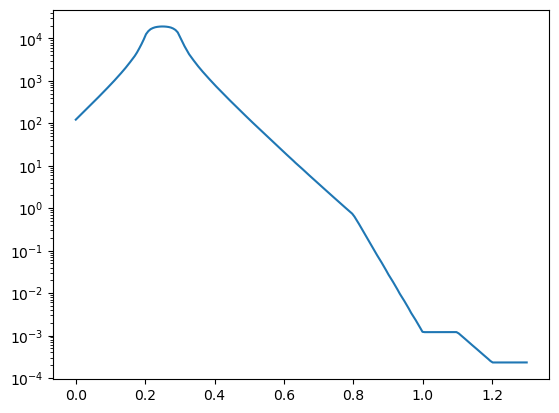

In [62]:
plt.semilogy(x, flux_interp)

In [36]:
mass_operator      = MassOperator(solution_domain.fem_matrices, solution_domain.precomputed_geometric_data)
transport_operator = TransportOperatorMultipleAnglesVmap(TransportOperatorVmap(solution_domain.solution_domain_data, topological_sorted_angles, 0))
moment_operator   =  MomentOperator.from_quadrature_set(quadrature_set, 1)

source_int = mass_operator.mv(sources[0]) # isotropic source

source_total = jnp.broadcast_to(source_int[None, :, :], (topological_sorted_angles.angle.shape[0],) + source_int.shape) # source for all angles

psik_ei = transport_operator.inv(source_total)
psi_ei_lm = moment_operator.mv(jnp.moveaxis(psik_ei, 0, -1))
print(psi_ei_lm[0,:])

from jax_sn.operators.scatter_operator.scatter_operator_util import InScatterOperator


scatter_op = InScatterOperator.from_quadrature_set_and_cross_sections(quadrature_set, solution_domain.domain.cross_sections_indexed, l_max = 1)


scatter_op.mv(psi_ei_lm)



[[ 8.94822195e+01  5.17580091e+00 -6.50070385e-15  1.31298504e+02]
 [ 8.95595867e+01 -3.97599679e+00 -7.55893409e-15  1.31389064e+02]
 [ 1.70138883e+02  8.49355244e+00 -1.39721982e-14  2.45543583e+02]
 [ 1.39517981e+02 -2.66295140e-01 -9.86132148e-15  2.01450212e+02]
 [ 1.23812769e+02  6.68698983e+00 -9.47956208e-15  1.80167970e+02]
 [ 1.02607574e+02 -3.22270169e-01 -8.39108697e-15  1.49212084e+02]]


Array([[[16.68173871, 16.68173871, 16.59037904, ..., 14.63822716, 13.99870951, 13.99870951],
        [16.61514914, 16.61514914, 16.68533069, ..., 14.08541544, 14.5766863 , 14.5766863 ],
        [31.67006173, 31.67006173, 31.52013941, ..., 27.78566292, 26.73620666, 26.73620666],
        [25.90726298, 25.90726298, 25.91196344, ..., 22.33730156, 22.37020476, 22.37020476],
        [23.06435357, 23.06435357, 22.94631945, ..., 20.23825535, 19.41201646, 19.41201646],
        [19.06153648, 19.06153648, 19.06722497, ..., 16.41068234, 16.45050177, 16.45050177]],

       [[16.3934233 , 16.3934233 , 16.46495993, ..., 13.8871781 , 14.38793451, 14.38793451],
        [31.36647556, 31.36647556, 31.491432  , ..., 26.67816483, 27.55285991, 27.55285991],
        [31.71630074, 31.71630074, 31.5660327 , ..., 27.82685733, 26.77498105, 26.77498105],
        [35.28618927, 35.28618927, 35.2951137 , ..., 30.45163648, 30.51410749, 30.51410749],
        [25.93708939, 25.93708939, 25.94203346, ..., 22.36278781, 22

In [339]:
from jax_sn.domain.geometric_domain import CrossSectionIndexed

from jax_sn.quadrature_set.quadrature_set_base import _lm_real_expansion

def _scatter_kernel_xs_indexed(elem_idx : int, g_out : int, g_in : int, cross_section_indexed : CrossSectionIndexed, moments_array : jnp.ndarray) -> jnp.ndarray:
    r'''
    Computes from a given element index, outgoing group, incoming group, indexed cross section object and buffer for the specific incoming group, the corresponding scattering scattering source:

    .. math::
        s^{g_{out}}_{lm}= \sum_l \sigma_{l, g_{out}\from g_{in}}^{(e)} \psi_{lm}^{(e, g_{in})}

    Automatically pads or truncates the cross section data to match the number of moments in the moments_array.
        
    Parameters
    ----------
    elem_idx : int
        The element index.
    g_out : int
        The outgoing energy group index.
    g_in : int
        The incoming energy group index.
    cross_section_indexed : CrossSectionIndexed
        The indexed cross section data structure.
    moments_array : jnp.ndarray [n_elements, n_basis, n_moments]
        The moments array containing angular flux moments.
    
    Returns
    -------
    jnp.ndarray [n_basis, n_moments]
        The scattering source moments for the specified element and energy groups.
    '''
    
    xs_idx = cross_section_indexed.indices[elem_idx]

    sigma_l_gg = cross_section_indexed.cross_section_data.scattering[xs_idx, :, g_out, g_in] # [lmax + 1]
    
    # Since this is a l expansion, not in terms of lm, we expand it locally to the full n_moments                                                                                            
    extended_sigma_lm_gg = sigma_l_gg[_lm_real_expansion(sigma_l_gg.shape[0] - 1)[0]] # [n_moments]


    # now we have to pad/truncate to match moments_array
    n_moments = moments_array.shape[-1]
    extended_sigma_lm_gg = extended_sigma_lm_gg[:n_moments]  #  first truncate if needed (if n_moments > extended_sigma_lm_gg.shape[0], this does nothing)
    extended_sigma_lm_gg = jnp.pad(extended_sigma_lm_gg, (0, n_moments - extended_sigma_lm_gg.shape[0]))  # pad if needed    


    return extended_sigma_lm_gg[None, :] * moments_array[elem_idx, :, :]  # [None, n_moments] * [n_basis, n_moments] -> [n_basis, n_moments]

    

_scatter_kernel_xs_indexed(0,0,0,solution_domain.domain.cross_sections_indexed, psi_ei_lm)


Array([[ 4.92769635e+02,  5.99651214e+00, -7.53150096e-15,  1.52118114e+02],
       [ 4.93195688e+02, -4.60645868e+00, -8.75753159e-15,  1.52223034e+02],
       [ 9.36937813e+02,  9.84034957e+00, -1.61877277e-14,  2.84478692e+02],
       [ 7.68311570e+02, -3.08520761e-01, -1.14250016e-14,  2.33393568e+02],
       [ 6.81824539e+02,  7.74732574e+00, -1.09827078e-14,  2.08736665e+02],
       [ 5.65049650e+02, -3.73371583e-01, -9.72163646e-15,  1.72872196e+02]], dtype=float64)

In [ ]:
def _moment_to_discrete_kernel(moment_array : jnp.ndarray, yklm : jnp.ndarray) -> jnp.ndarray:
    r'''
    Converts a moment array to discrete angles using the yklm matrix.

    .. math::
        \psi^{(e, g, a)} = \sum_{lm} Y_{klm} \psi_{lm}^{(e, g)}

    Parameters
    ----------
    moment_array : jnp.ndarray [n_basis, n_moments]
        The moment array for a specific element and energy group.
    yklm : jnp.ndarray [n_angles, n_moments]
        The yklm matrix for the quadrature set.

    Returns
    -------
    jnp.ndarray [n_basis, n_angles]
        The discrete angular flux for the specified element and energy group.
    '''
    assert moment_array.shape[-1] == yklm.shape[-1], f"Moment array last dimension {moment_array.shape} must match yklm last dimension {yklm.shape}."
    return jnp.einsum('...l,kl->...k', moment_array, yklm)  # [..., n_moments] x [n_angles, n_moments] -> [...., n_angles]


quadrature_set.ylm_real(4)


Array([[ 2.82094792e-01,  6.84180366e-02, -4.78926256e-01, ..., -1.95126358e-17,  9.52780883e-03, -9.62454034e-04],
       [ 2.82094792e-01,  6.84180366e-02,  4.78926256e-01, ..., -1.95126358e-17, -9.52780883e-03, -9.62454034e-04],
       [ 2.82094792e-01, -6.84180366e-02, -4.78926256e-01, ..., -1.95126358e-17,  9.52780883e-03, -9.62454034e-04],
       ...,
       [ 2.82094792e-01,  4.78926256e-01,  6.84180366e-02, ...,  3.84144744e-01,  9.93614350e-02,  5.07213276e-01],
       [ 2.82094792e-01, -4.78926256e-01, -6.84180366e-02, ...,  3.84144744e-01, -9.93614350e-02,  5.07213276e-01],
       [ 2.82094792e-01, -4.78926256e-01,  6.84180366e-02, ...,  3.84144744e-01,  9.93614350e-02,  5.07213276e-01]], dtype=float64)

In [363]:
quadrature_set.weights.sum()

Array(12.56637061, dtype=float64)

In [ ]:
from jax_sn.operators.base_linear_operator import AbstractLinearOperator_sn
class InScatterOperator(AbstractLinearOperator_sn):


    def 